## COUNTER — Connect Four

## 1. Preparación del entorno
Ejecutar desde el kernel Python de Poetry, normalmente ubicado en `connect_four/.venv/bin/python`. Esta celda detecta automáticamente la raíz `connect_four` al ejecutar el notebook desde `connect_four/` o `connect_four/notebooks/`.

In [1]:
from pathlib import Path
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in candidates if (p / "board.py").exists() and (p / "src" / "agents.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Abrí Jupyter desde connect_four/ o connect_four/notebooks/ y verificá src/agents.py")
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"
NB_RESULTS = RESULTS / "notebook_counter"
NB_RESULTS.mkdir(parents=True, exist_ok=True)
print("Raíz del proyecto:", ROOT)
print("Python:", sys.executable)
print("Resultados del notebook:", NB_RESULTS)

Raíz del proyecto: /Users/tatiana/Desktop/IA/Obligatorio_IA_Agosto_2026/obligatorio-ia/connect_four
Python: /Users/tatiana/Desktop/IA/Obligatorio_IA_Agosto_2026/.venv/bin/python
Resultados del notebook: /Users/tatiana/Desktop/IA/Obligatorio_IA_Agosto_2026/obligatorio-ia/connect_four/results/notebook_counter


## 2. Verificación de las reglas originales
La variante captura horizontal y diagonalmente, nunca verticalmente. En el código entregado `add_tile()` comprueba las capturas una segunda vez después de `occupy_space()`. Conservamos el comportamiento del tablero y verificamos el caso simple de idempotencia.


In [2]:
from board import Board
from stratego_agent import Stratego
from src.agents import SearchAgent, RandomAgent
from src.heuristics import PRESETS, evaluate
from src.tournament import play

b = Board(6, 7)
b.add_tile(0, 1)
b.add_tile(1, 2)
b.add_tile(2, 1)
assert list(b._grid[5, :3]) == [1, 1, 1], "Falló captura horizontal"

vertical = Board(6, 7)
for player in (1, 2, 1):
    vertical.add_tile(0, player)
assert list(vertical._grid[-3:, 0]) == [1, 2, 1], "Se produjo captura vertical inesperada"

snapshot = b._grid.copy()
b._add_connectedd_tiles((5, 2))
assert np.array_equal(snapshot, b._grid), "La segunda captura cambió el tablero en el caso de prueba"
assert Stratego(2, 4).IlllIIllIII == 1, "Revisar mapeo de jugadores Stratego"
assert Stratego(1, 4).IlllIIllIII == 2, "Revisar mapeo de jugadores Stratego"

print("OK: captura horizontal, sin captura vertical, doble llamada en caso simple y jugadores Stratego")
print("Acciones legales iniciales:", Board(6,7).get_posible_actions())

OK: captura horizontal, sin captura vertical, doble llamada en caso simple y jugadores Stratego
Acciones legales iniciales: [0, 1, 2, 3, 4, 5, 6]


## 3. Tablero y agente inteligente
El agente implementa `next_action(board)` y `heuristic_utility(board)`, heredando de `Agent`. La heurística `balanced` combina ventanas abiertas, control central, fichas, potencial de captura y amenazas inmediatas. En terminales, la búsqueda prioriza victorias y derrotas antes que la heurística.

In [3]:
from agent import Agent
agent_demo = SearchAgent(
    player=1, depth=3, algorithm="minimax",
    pruning=True, ordering=True, heuristic="balanced",
    seed=42, random_ties=False,
)
assert isinstance(agent_demo, Agent)
initial_board = Board(6, 7)
action = agent_demo.next_action(initial_board)
assert action in initial_board.get_posible_actions()
print("Acción inicial:", action)
print("Nodos evaluados:", agent_demo.nodes)
print("Tiempo de búsqueda (s):", round(agent_demo.elapsed, 5))
print("Heurísticas disponibles:", ", ".join(PRESETS))

Acción inicial: 2
Nodos evaluados: 181
Tiempo de búsqueda (s): 0.07875
Heurísticas disponibles: windows, center, material, capture, immediate, balanced, tactical


## 4. Visualización de una partida contra Stratego
Se simula una partida **sin `input()` ni render textual obligatorio**. Para cada turno se registra el tablero, el jugador que mueve y la decisión adoptada. La partida termina cuando `board.is_final()`; el ganador se determina con `board.winner`, **no** con la recompensa del entorno.

Se utiliza `Stratego(1,4)` cuando Stratego es el jugador 2, ya que su constructor intercambia internamente el identificador. El experimento completo del informe utiliza aperturas variadas; esta partida es únicamente una **demostración**.

In [4]:
def partida_demostracion(own_player=1, seed=44, depth=3, opening_random=2):
    board = Board(6, 7)
    own = SearchAgent(player=own_player, depth=depth, algorithm="minimax",
                      heuristic="balanced", pruning=True, ordering=True,
                      seed=seed, random_ties=False)
    adversary_player = 3 - own_player
    adversary = Stratego(1 if adversary_player == 2 else 2, 4)
    rng = random.Random(seed)
    frames = [board._grid.copy()]
    history = []
    for turn in range(42):
        if board.is_final():
            break
        to_move = 1 if turn % 2 == 0 else 2
        legal = board.get_posible_actions()
        if turn < opening_random:
            action = rng.choice(legal)
            who = "apertura aleatoria"
        elif to_move == own_player:
            action = own.next_action(board)
            who = "Minimax"
        else:
            action = adversary.next_action(board)
            who = "Stratego"
        if action not in legal:
            raise ValueError(f"Movimiento ilegal: {action}, legales={legal}")
        board.add_tile(action, to_move)
        history.append({"turn": turn+1, "player": to_move, "agent": who,
                        "column": action, "winner_after_move": board.winner})
        frames.append(board._grid.copy())
    return board, pd.DataFrame(history), frames

board_end, history, frames = partida_demostracion(own_player=1, seed=44)
display(history)
print("Ganador:", board_end.winner, "| Movimientos:", len(history))
history.to_csv(NB_RESULTS / "partida_demo_movimientos.csv", index=False)

,turn,player,agent,column,winner_after_move
0,1,1,apertura aleatoria,3,0
1,2,2,apertura aleatoria,4,0
2,3,1,Minimax,5,0
3,4,2,Stratego,4,0
4,5,1,Minimax,2,1


Ganador: 1 | Movimientos: 5


### Visualizar el tablero final y algunos estados intermedios
Los colores identifican **jugador 1**, **jugador 2** y celdas vacías. Es una ilustración estática obtenida del tablero real; las capturas se reflejan automáticamente en la grilla.

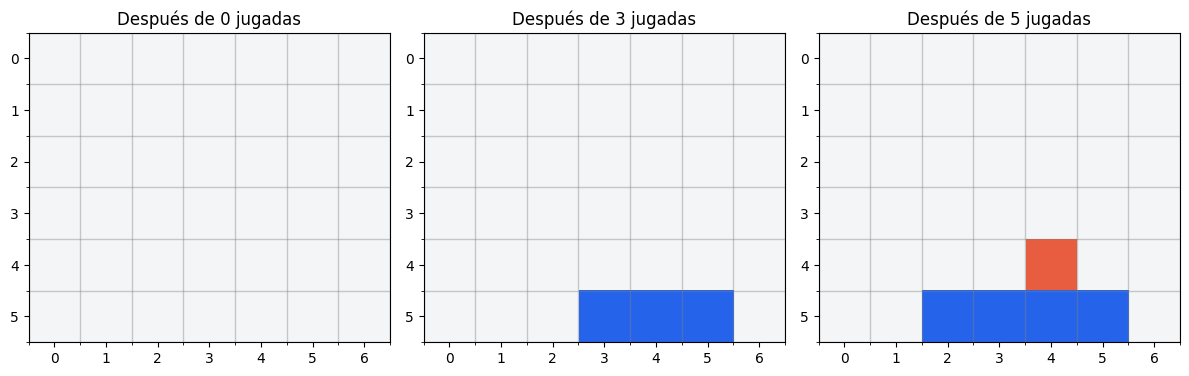

In [5]:
from matplotlib.colors import ListedColormap, BoundaryNorm
cmap = ListedColormap(["#f4f5f7", "#2563eb", "#e85d3f"])
norm = BoundaryNorm([-0.5,0.5,1.5,2.5], cmap.N)
def mostrar_tableros(frames, indices, filename):
    fig, axes = plt.subplots(1,len(indices),figsize=(4*len(indices),4),squeeze=False)
    for ax, ix in zip(axes[0], indices):
        ax.imshow(frames[ix],cmap=cmap,norm=norm)
        ax.set_title(f"Después de {ix} jugadas")
        ax.set_xticks(range(7))
        ax.set_yticks(range(6))
        ax.set_xticks(np.arange(-.5,7,1),minor=True)
        ax.set_yticks(np.arange(-.5,6,1),minor=True)
        ax.grid(which='minor',linewidth=1,color='gray',alpha=.4)
    plt.tight_layout()
    plt.savefig(filename,dpi=180)
    plt.show()
    plt.close(fig)

indices = sorted(set([0, len(frames)//2, len(frames)-1]))
mostrar_tableros(frames, indices, NB_RESULTS / "partida_demo_tableros.png")

## 5. Minimax y Expectimax: comparación sobre una misma posición
Esta celda compara decisiones y costos de los algoritmos en la misma posición. **No es una prueba estadística de cuál juega mejor**: para ello se usan los torneos de la sección 7.

In [6]:
position = Board(6,7)
for player,col in [(1,3),(2,2),(1,3),(2,2),(1,4),(2,1)]:
    position.add_tile(col,player)
    if position.is_final(): break
assert not position.is_final()
rows = []
for name,kwargs in [
    ("Minimax sin poda",dict(algorithm='minimax',pruning=False,ordering=False)),
    ("Minimax α-β",dict(algorithm='minimax',pruning=True,ordering=False)),
    ("Minimax α-β + orden",dict(algorithm='minimax',pruning=True,ordering=True)),
    ("Expectimax uniforme",dict(algorithm='expectimax',chance='uniform')),
    ("Expectimax ponderado",dict(algorithm='expectimax',chance='softmax')),
]:
    a=SearchAgent(player=1,depth=3,heuristic='windows',random_ties=False,**kwargs)
    move=a.next_action(position)
    rows.append(dict(algorithm=name,action=move,search_value=a.last_value,
                     nodes=a.nodes,seconds=a.elapsed))
comparison = pd.DataFrame(rows)
display(comparison)
comparison.to_csv(NB_RESULTS / 'busqueda_posicion_ejemplo.csv',index=False)
assert comparison.loc[0,'search_value'] == comparison.loc[1,'search_value'] == comparison.loc[2,'search_value']
print('OK: Minimax con y sin poda devuelve el mismo valor en esta posición')

,algorithm,action,search_value,nodes,seconds
0,Minimax sin poda,1,4.200000e+01,400,0.077369
1,Minimax α-β,1,4.200000e+01,291,0.018479
2,Minimax α-β + orden,1,4.200000e+01,253,0.015318
3,Expectimax uniforme,5,8.571429e+08,400,0.025115
4,Expectimax ponderado,5,8.570590e+08,400,0.027748


OK: Minimax con y sin poda devuelve el mismo valor en esta posición


## 6. Resultados experimentales existentes
Estas celdas **leen** los CSV/JSON producidos anteriormente mediante los comandos `python -m src.benchmark`, `python -m src.tournament` y `python -m src.plot_results`. No inventan resultados y no ejecutan torneos largos automáticamente. Si falta un archivo, se informa como pendiente.

Experimentos de referencia: `benchmark_poda_d4`, `minimax_vs_random`, `minimax_vs_expectimax`, `minimax_vs_stratego_20`, las tres profundidades y las siete heurísticas.

In [7]:
names = [
    'benchmark_poda_d4', 'minimax_vs_random', 'minimax_vs_expectimax',
    'minimax_vs_stratego_20',
    'minimax_depth_2', 'minimax_depth_3', 'minimax_depth_4',
    'heuristic_windows', 'heuristic_center', 'heuristic_material',
    'heuristic_capture', 'heuristic_immediate', 'heuristic_balanced',
    'heuristic_tactical'
]
rows=[]
for name in names:
    f=RESULTS/f'{name}.json'
    if not f.exists():
        rows.append({'experiment':name,'status':'PENDIENTE'})
        continue
    data=json.loads(f.read_text())
    if isinstance(data, list):
        rows.append({'experiment':name,'status':'OK', 'variants':len(data)})
    else:
        rows.append({'experiment':name,'status':'OK',
                     'games':data.get('games'), 'wins':data.get('wins'),
                     'draws':data.get('draws'), 'losses':data.get('losses'),
                     'win_rate':data.get('win_rate'),
                     'mean_moves':data.get('mean_moves'),
                     'mean_decision_ms':1000*data.get('mean_decision_seconds',float('nan'))})
summary=pd.DataFrame(rows)
display(summary)
summary.to_csv(NB_RESULTS/'resumen_experimentos.csv',index=False)
print('Experimentos completos:',(summary.status=='OK').sum(),'/',len(summary))

,experiment,status,variants,games,wins,draws,losses,win_rate,mean_moves,mean_decision_ms
0,benchmark_poda_d4,OK,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,minimax_vs_random,OK,NaN,20.0,20.0,0.0,0.0,1.0,8.0,28.724875
2,minimax_vs_expectimax,OK,NaN,20.0,16.0,0.0,4.0,0.8,8.1,25.330269
3,minimax_vs_stratego_20,OK,NaN,20.0,14.0,0.0,6.0,0.7,8.9,29.119024
4,minimax_depth_2,OK,NaN,20.0,20.0,0.0,0.0,1.0,7.9,10.011670
5,minimax_depth_3,OK,NaN,20.0,20.0,0.0,0.0,1.0,8.0,29.350691
6,minimax_depth_4,OK,NaN,20.0,20.0,0.0,0.0,1.0,8.2,132.547022
7,heuristic_windows,OK,NaN,20.0,20.0,0.0,0.0,1.0,8.1,9.797459
8,heuristic_center,OK,NaN,20.0,20.0,0.0,0.0,1.0,9.4,3.145510
9,heuristic_material,OK,NaN,20.0,20.0,0.0,0.0,1.0,9.7,2.454602


Experimentos completos: 14 / 14


## 7. Gráficos comparativos a partir de resultados reales

,nodes,seconds
variant,,
Sin poda,2207.95,0.147861
Poda α-β,965.15,0.058723
Poda + orden,698.85,0.040906


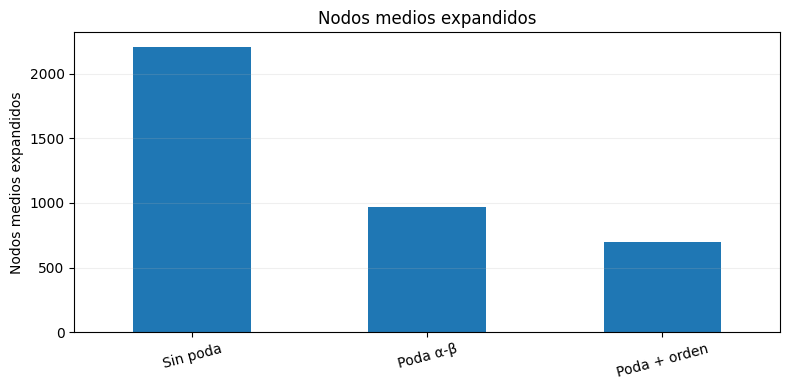

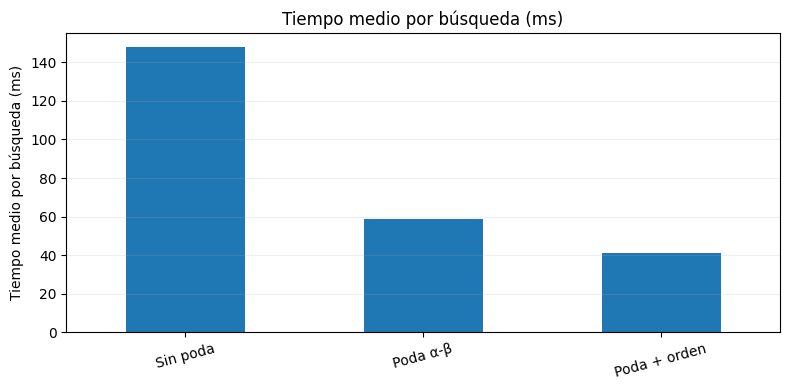

In [8]:
# Benchmark de poda: resultados concretos sin ejecutar nuevas búsquedas.
bench_path=RESULTS/'benchmark_poda_d4.csv'
if bench_path.exists():
    df=pd.read_csv(bench_path)
    labels=[]
    for _,r in df.iterrows():
        labels.append('Sin poda' if not bool(r['pruning']) else ('Poda + orden' if bool(r['ordering']) else 'Poda α-β'))
    df['variant']=labels
    agg=df.groupby('variant',sort=False).agg(nodes=('nodes','mean'),seconds=('seconds','mean'))
    display(agg)
    for metric,title,filename,factor in [
        ('nodes','Nodos medios expandidos','comparacion_poda_nodos.png',1),
        ('seconds','Tiempo medio por búsqueda (ms)','comparacion_poda_tiempo.png',1000)
    ]:
        fig,ax=plt.subplots(figsize=(8,4))
        (agg[metric]*factor).plot.bar(ax=ax)
        ax.set_title(title);ax.set_xlabel('');ax.set_ylabel(title)
        ax.tick_params(axis='x',labelrotation=15)
        ax.grid(axis='y',alpha=.2)
        fig.tight_layout();fig.savefig(NB_RESULTS/filename,dpi=180)
        plt.show();plt.close(fig)
else:
    print('No existe benchmark_poda_d4.csv; ejecutar src.benchmark antes de generar estas figuras.')

,depth,win_rate,mean_time_ms,mean_nodes
0,2,1.0,10.011670,39.455179
1,3,1.0,29.350691,153.227381
2,4,1.0,132.547022,635.469444


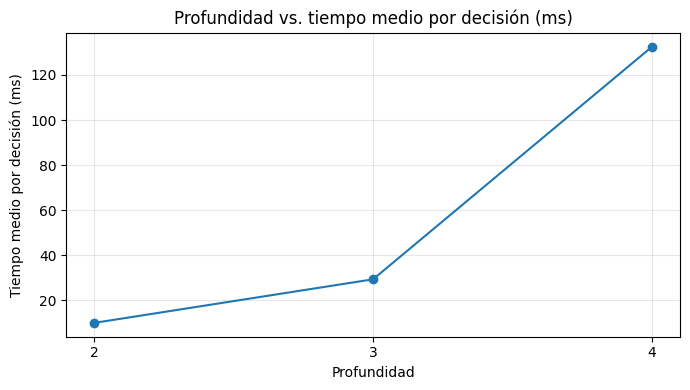

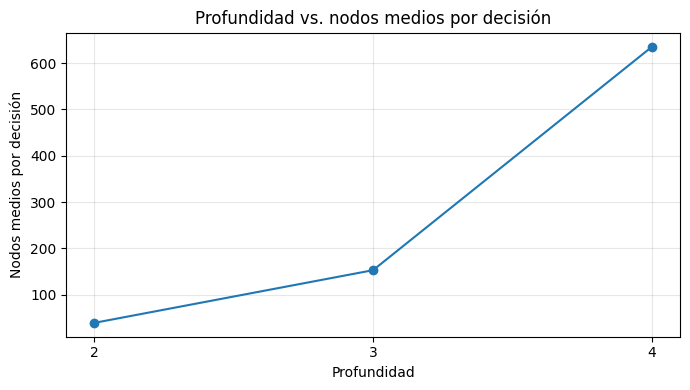

In [9]:
# Gráfico consolidado: profundidad frente a tiempo/nodos y tasa de victoria.
depth_rows=[]
for depth in (2,3,4):
    f=RESULTS/f'minimax_depth_{depth}.json'
    if f.exists():
        data=json.loads(f.read_text())
        depth_rows.append(dict(depth=depth,win_rate=data['win_rate'],
                               mean_time_ms=data['mean_decision_seconds']*1000,
                               mean_nodes=data['mean_nodes_per_move']))
depths=pd.DataFrame(depth_rows)
if len(depths):
    display(depths)
    depths.to_csv(NB_RESULTS/'comparacion_profundidades.csv',index=False)
    for col,label in [('mean_time_ms','Tiempo medio por decisión (ms)'),('mean_nodes','Nodos medios por decisión')]:
        fig,ax=plt.subplots(figsize=(7,4))
        ax.plot(depths['depth'],depths[col],marker='o')
        ax.set_xticks(depths['depth']);ax.set_xlabel('Profundidad');ax.set_ylabel(label)
        ax.set_title(f'Profundidad vs. {label.lower()}');ax.grid(alpha=.3)
        fig.tight_layout();fig.savefig(NB_RESULTS/f'profundidad_{col}.png',dpi=180)
        plt.show();plt.close(fig)
else:
    print('No se encontraron JSON de comparación de profundidades.')

,heuristic,win_rate,mean_moves,mean_time_ms,mean_nodes
0,windows,1.0,8.1,9.797459,153.253095
1,center,1.0,9.4,3.145510,137.781270
2,material,1.0,9.7,2.454602,137.561706
3,capture,1.0,8.5,5.528792,141.700992
4,immediate,1.0,8.4,16.810473,143.675595
5,balanced,1.0,8.0,29.274392,153.227381
6,tactical,1.0,7.7,29.483844,150.801548


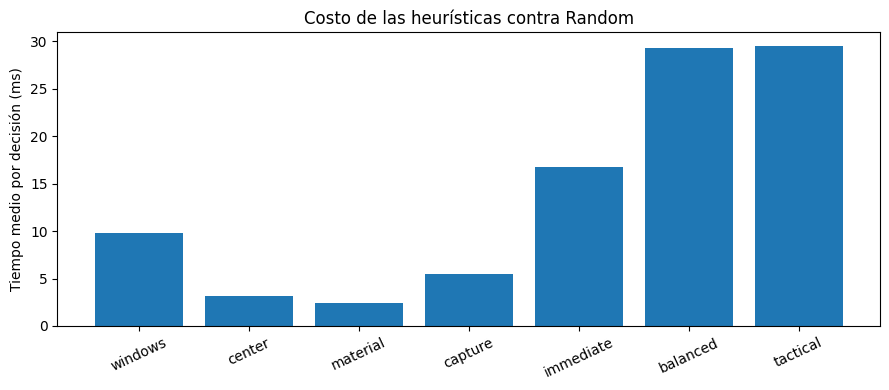

Efecto techo: todas las heurísticas presentan la misma tasa de victoria; evaluar contra Stratego.


In [10]:
# Heurísticas: comprobar efecto techo frente a Random y comparar tiempo.
h_names=['windows','center','material','capture','immediate','balanced','tactical']
h_rows=[]
for h in h_names:
    f=RESULTS/f'heuristic_{h}.json'
    if f.exists():
        d=json.loads(f.read_text())
        h_rows.append({'heuristic':h,'win_rate':d['win_rate'],
                       'mean_moves':d['mean_moves'],
                       'mean_time_ms':d['mean_decision_seconds']*1000,
                       'mean_nodes':d['mean_nodes_per_move']})
heuristics=pd.DataFrame(h_rows)
if len(heuristics):
    display(heuristics)
    heuristics.to_csv(NB_RESULTS/'comparacion_heuristicas.csv',index=False)
    fig,ax=plt.subplots(figsize=(9,4))
    ax.bar(heuristics['heuristic'],heuristics['mean_time_ms'])
    ax.tick_params(axis='x',labelrotation=25)
    ax.set_ylabel('Tiempo medio por decisión (ms)')
    ax.set_title('Costo de las heurísticas contra Random')
    fig.tight_layout();fig.savefig(NB_RESULTS/'heuristicas_tiempo.png',dpi=180)
    plt.show();plt.close(fig)
    if heuristics.win_rate.nunique()==1:
        print('Efecto techo: todas las heurísticas presentan la misma tasa de victoria; evaluar contra Stratego.')
else:
    print('No se encontraron resultados de heurísticas en results/.')

## 8. Experimento reproducible rápido: Minimax frente a Stratego
Las celdas siguientes ejecutan **dos partidas por lado** con aperturas aleatorias, suficientes para validar que los agentes se integran. Las 20 partidas del informe corresponden a `minimax_vs_stratego_20` y se conservan en `results/`. No reemplazar la evaluación amplia por esta demostración.

In [11]:
quick=[]
for swap in (False,True):
    for seed in (101,102):
        result=play('minimax','stratego',depth=3,heuristic='balanced',seed=seed,
                    swap=swap,opening_random=2)
        quick.append(result)
quick_df=pd.DataFrame(quick)
display(quick_df[['seed','a_player','outcome','moves','a_mean_decision_seconds','a_mean_nodes_per_move']])
quick_df.to_csv(NB_RESULTS/'verificacion_stratego.csv',index=False)
print('Victorias:',(quick_df.outcome=='win').sum(),'de',len(quick_df))

,seed,a_player,outcome,moves,a_mean_decision_seconds,a_mean_nodes_per_move
0,101,1,win,7,0.029481,156.750000
1,102,1,win,13,0.033824,171.285714
2,101,2,loss,7,0.028976,140.333333
3,102,2,loss,17,0.025119,135.250000


Victorias: 2 de 4


## 9. Síntesis para el informe y archivos de entrega

Los gráficos y tablas del notebook se guardan en `results/notebook_counter/`. Los experimentos principales quedan en `results/`.

**Limitaciones metodológicas:** 20 partidas por configuración pueden ser insuficientes para conclusiones generales; Random genera efecto techo; las aperturas aleatorias son limitadas; el resultado frente a Stratego cambia entre jugar primero y segundo. La captura convierte el problema en una variante distinta del Connect Four clásico.

**Conclusión provisional:** usar Minimax con poda α-β, ordenamiento y heurística `balanced` como configuración de referencia; comparar después las heurísticas contra Stratego antes de elegir una definitiva.

In [13]:
files=sorted(NB_RESULTS.glob('*'))
manifest={'notebook':'notebooks/Connect_four_COUNTER_revisado.ipynb',
          'demonstration':'Minimax α-β depth=3 vs Stratego depth=4',
          'generated_files':[str(p.relative_to(ROOT)) for p in files],
          'source_result_files':[str(p.relative_to(ROOT)) for p in sorted(RESULTS.glob('*.json'))]}
(NB_RESULTS/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
print('Archivos generados:')
for path in sorted(NB_RESULTS.glob('*')):
    print(' -',path.relative_to(ROOT))

Archivos generados:
 - results/notebook_counter/busqueda_posicion_ejemplo.csv
 - results/notebook_counter/comparacion_heuristicas.csv
 - results/notebook_counter/comparacion_poda_nodos.png
 - results/notebook_counter/comparacion_poda_tiempo.png
 - results/notebook_counter/comparacion_profundidades.csv
 - results/notebook_counter/heuristicas_tiempo.png
 - results/notebook_counter/manifest.json
 - results/notebook_counter/partida_demo_movimientos.csv
 - results/notebook_counter/partida_demo_tableros.png
 - results/notebook_counter/profundidad_mean_nodes.png
 - results/notebook_counter/profundidad_mean_time_ms.png
 - results/notebook_counter/resumen_experimentos.csv
 - results/notebook_counter/verificacion_stratego.csv
